In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import pandas as pd

In [14]:
#PLT 한글 깨짐 방지코드
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [8]:
from pathlib import Path

import pandas as pd


# 주피터 노트북에서는 __file__이 없으므로 CSV 폴더 경로를 직접 지정합니다.
# 노트북 실행 위치(cwd)는 practice/day32 이므로 ../../ 로 저장소 루트까지 올라갑니다.
BASE = Path("../../lectures/week9/3일차실습_20_261109_11")
data = BASE / "03-02_센서_고장_판별_이상구간샘플.csv"
EVENTS = BASE / "03-02_센서_고장_판별_정비알람이력.csv"

df = pd.read_csv(data, parse_dates=["timestamp"])
events = pd.read_csv(EVENTS, parse_dates=["event_time"])
print("shape:", df.shape)
print(df.isna().sum())
print(events.to_string(index=False))


shape: (288, 10)
timestamp           0
MTR02_TEMP          0
MTR02_TEMP_B        0
MTR02_VIB_H        18
MTR02_CURRENT       0
MTR02_RUN           0
HYD02_PRESS         0
HYD02_PRESS_ACC     0
HYD02_FLOW          0
FUR02_TEMP_Z1       0
dtype: int64
         event_time             tag event_type               description
2026-04-01 18:00:00       MTR02_RUN       설비정지          계획 정지 - 소재 교체 작업
2026-04-01 21:00:00       MTR02_RUN       설비정지             정지 해제 - 운전 재개
2026-04-02 06:00:00     MTR02_VIB_H       통신장애           계측 네트워크 스위치 재기동
2026-04-02 09:00:00     MTR02_VIB_H       통신장애                  통신 복구 확인
2026-04-02 12:00:00 HYD02_PRESS_ACC         알람           어큐뮬레이터 압력 상한 도달
2026-04-01 10:00:00     HYD02_PRESS         알람            공급 압력 변동 없음 경고
2026-03-15 09:00:00      MTR02_TEMP         교정 베어링 온도 센서 정기 교정 - 보정량 미기재
2026-02-20 14:00:00      HYD02_FLOW       센서교체            유량계 교체 - 동일 사양


In [ ]:
# TODO 1: MTR02 / HYD02 / FUR02 케이스 중 하나를 골라 물리량과 단위를 정리하세요.


In [9]:

tag_info = {
    "MTR02_TEMP":    {"물리량": "베어링 온도 (센서 1)",          "단위": "degC (추정)", "참고 태그": "FAN01_TEMP (degC)"},
    "MTR02_TEMP_B":  {"물리량": "베어링 온도 (센서 2, 비교용)",   "단위": "degC (추정)", "참고 태그": "FAN01_TEMP (degC)"},
    "MTR02_VIB_H":   {"물리량": "수평 진동 속도 RMS",             "단위": "mm/s (추정)", "참고 태그": "MTR01_VIB_H (mm/s)"},
    "MTR02_CURRENT": {"물리량": "모터 전류",                      "단위": "A (추정)",    "참고 태그": "MTR01_CURRENT (A)"},
    "MTR02_RUN":     {"물리량": "가동 상태 (1=운전, 0=정지)",      "단위": "없음",        "참고 태그": "없음 (0/1 플래그)"},
}

tag_table = pd.DataFrame(tag_info).T
print(tag_table.to_string())


                              물리량         단위               참고 태그
MTR02_TEMP          베어링 온도 (센서 1)  degC (추정)   FAN01_TEMP (degC)
MTR02_TEMP_B   베어링 온도 (센서 2, 비교용)  degC (추정)   FAN01_TEMP (degC)
MTR02_VIB_H          수평 진동 속도 RMS  mm/s (추정)  MTR01_VIB_H (mm/s)
MTR02_CURRENT               모터 전류     A (추정)   MTR01_CURRENT (A)
MTR02_RUN      가동 상태 (1=운전, 0=정지)         없음        없음 (0/1 플래그)


In [6]:
# TODO 2: 결측 구간, 가동 중 최장 동일값 반복, 최대값 반복 횟수, 구간별 변동 폭을 계산하세요.


In [25]:
# 결측 구간 찾기 (한 줄)
missing_times = df.loc[df["MTR02_VIB_H"].isna(), "timestamp"]

print("결측 개수:", len(missing_times))
print("결측 시작:", missing_times.min())
print("결측 끝:", missing_times.max())


결측 개수: 18
결측 시작: 2026-04-02 06:00:00
결측 끝: 2026-04-02 08:50:00


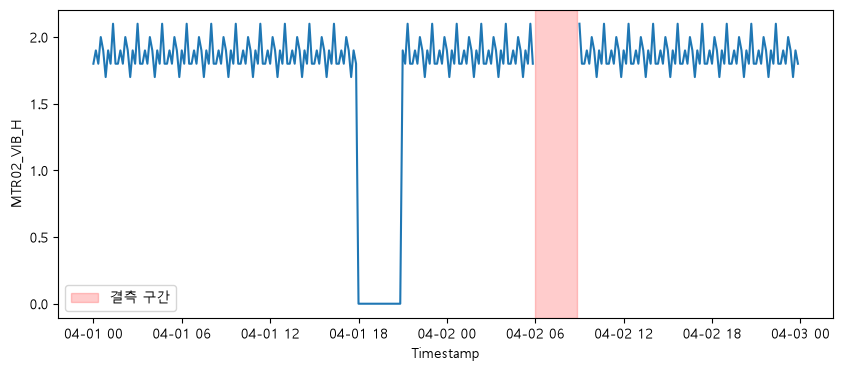

In [73]:

plt.figure(figsize=(10, 4))
plt.plot(df['timestamp'], df['MTR02_VIB_H'])               # x축: 시간
plt.axvspan(missing_times.min(), missing_times.max(), color='red', alpha=0.2, label='결측 구간')  # 결측 구간 색칠
plt.xlabel('Timestamp')
plt.ylabel('MTR02_VIB_H')
plt.legend()
plt.show()


In [47]:
# TODO 2: 결측 구간, 가동 중 최장 동일값 반복, 최대값 반복 횟수, 구간별 변동 폭을 계산하세요.


In [74]:
m2 = df[df["MTR02_RUN"] == 1]
m2.head()

,timestamp,MTR02_TEMP,MTR02_TEMP_B,MTR02_VIB_H,MTR02_CURRENT,MTR02_RUN,HYD02_PRESS,HYD02_PRESS_ACC,HYD02_FLOW,FUR02_TEMP_Z1
0,2026-04-01 00:00:00,48.0,48.0,1.8,62.5,1,152.0,148.0,118.0,1195.0
1,2026-04-01 00:10:00,48.0,48.0,1.9,63.0,1,153.0,148.0,118.5,1196.0
2,2026-04-01 00:20:00,48.5,48.5,1.8,62.0,1,152.0,147.0,117.5,1194.0
3,2026-04-01 00:30:00,48.0,48.0,2.0,64.0,1,151.0,148.0,118.0,1195.0
4,2026-04-01 00:40:00,48.5,48.5,1.9,63.5,1,153.0,149.0,118.5,1196.0


In [46]:
m2.columns.tolist()

['timestamp',
 'MTR02_TEMP',
 'MTR02_TEMP_B',
 'MTR02_VIB_H',
 'MTR02_CURRENT',
 'MTR02_RUN',
 'HYD02_PRESS',
 'HYD02_PRESS_ACC',
 'HYD02_FLOW',
 'FUR02_TEMP_Z1']

In [65]:
cols = ["MTR02_TEMP", "MTR02_TEMP_B", "MTR02_VIB_H", "MTR02_CURRENT"]



In [66]:
#가동 중 최장 동일값 반복

for col in cols:
    s = m2[col]
    결과 = s.groupby(s.ne(s.shift()).cumsum()).agg(["first", "size"]).sort_values("size").iloc[-1]
    print(col, "값:", 결과["first"], "연속:", 결과["size"])

#MTR02_TEMP 값: 50.0 연속: 4.0


MTR02_TEMP 값: 50.0 연속: 4.0
MTR02_TEMP_B 값: 54.0 연속: 3.0
MTR02_VIB_H 값: 1.8 연속: 2.0
MTR02_CURRENT 값: 62.0 연속: 1.0


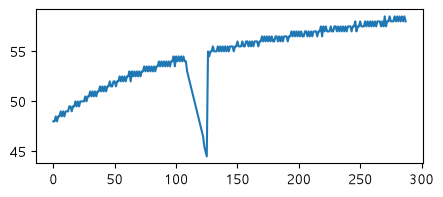

In [69]:
plt.figure(figsize=(5, 2))
plt.plot(df['MTR02_TEMP'])
plt.show()

In [68]:
#최대값 반복 횟수

for col in cols:
    s = m2[col]
    print(col, "최대값:", s.max(), "/ 반복 횟수:", (s == s.max()).sum())

#MTR02_TEMP_B 최대값: 54.0 / 반복 횟수: 58


MTR02_TEMP 최대값: 58.5 / 반복 횟수: 7
MTR02_TEMP_B 최대값: 54.0 / 반복 횟수: 58
MTR02_VIB_H 최대값: 2.1 / 반복 횟수: 25
MTR02_CURRENT 최대값: 64.5 / 반복 횟수: 26


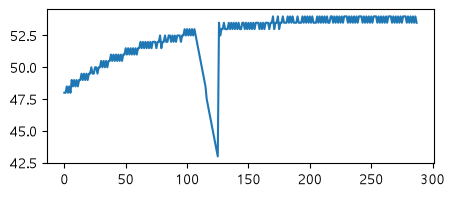

In [53]:
plt.figure(figsize=(5, 2))
plt.plot(df['MTR02_TEMP_B'])
plt.show()

In [61]:
df_run = df[df["MTR02_RUN"] == 1].set_index("timestamp")   

최대 = df_run["HYD02_FLOW"].resample("6h").max()
최소 = df_run["HYD02_FLOW"].resample("6h").min()
변동 = 최대 - 최소                       

처음 = 변동.iloc[0]                      
마지막 = 변동.iloc[-1]                   
print("처음:", round(처음, 2), "마지막:", round(마지막, 2))
print("차이:", round(마지막 - 처음, 2))
print("배율:", round(마지막 / 처음, 2), "배")


처음: 1.5 마지막: 5.7
차이: 4.2
배율: 3.8 배


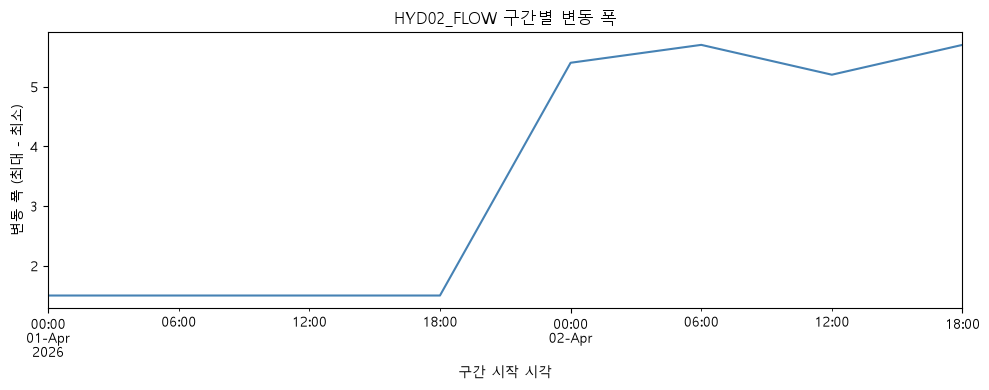

In [64]:
df_run = df[df["MTR02_RUN"] == 1].set_index("timestamp")   
최대 = df_run["HYD02_FLOW"].resample("6h").max()
최소 = df_run["HYD02_FLOW"].resample("6h").min()
변동 = 최대 - 최소                                         

plt.figure(figsize=(10, 4))
변동.plot(kind="line", color="steelblue")                  
plt.xticks(rotation=0)
plt.xlabel("구간 시작 시각")
plt.ylabel("변동 폭 (최대 - 최소)")
plt.title("HYD02_FLOW 구간별 변동 폭")
plt.tight_layout()
plt.show()


In [ ]:
# TODO 3: 같은 물리량 센서끼리 비교하고 알람·정비 이력과 시각을 대조하세요.

2026-04-01 18:00:00,MTR02_RUN,설비정지,계획 정지 - 소재 교체 작업
2026-04-01 21:00:00,MTR02_RUN,설비정지,정지 해제 - 운전 재개
2026-04-02 06:00:00,MTR02_VIB_H,통신장애,계측 네트워크 스위치 재기동
2026-04-02 09:00:00,MTR02_VIB_H,통신장애,통신 복구 확인

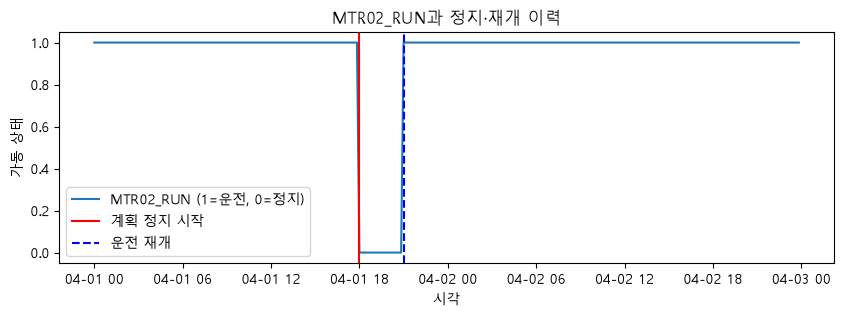

In [86]:
plt.figure(figsize=(10, 3))
plt.plot(df["timestamp"], df["MTR02_RUN"], label="MTR02_RUN (1=운전, 0=정지)")
plt.axvline(pd.Timestamp("2026-04-01 18:00:00"), color="red", linestyle="-", label="계획 정지 시작")
plt.axvline(pd.Timestamp("2026-04-01 21:00:00"), color="blue", linestyle="--", label="운전 재개")
plt.xlabel("시각")
plt.ylabel("가동 상태")
plt.title("MTR02_RUN과 정지·재개 이력")
plt.legend()
plt.show()


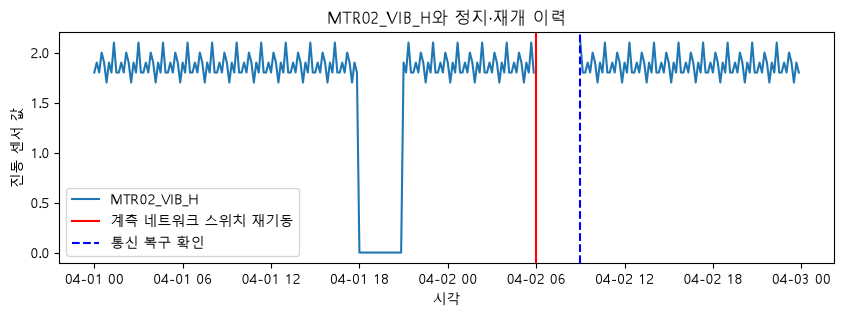

In [85]:
plt.figure(figsize=(10, 3))
plt.plot(df["timestamp"], df["MTR02_VIB_H"], label="MTR02_VIB_H")
plt.axvline(pd.Timestamp("2026-04-02 06:00:00"), color="red", linestyle="-", label="계측 네트워크 스위치 재기동")
plt.axvline(pd.Timestamp("2026-04-02 09:00:00"), color="blue", linestyle="--", label="통신 복구 확인")
plt.xlabel("시각")
plt.ylabel("진동 센서 값")
plt.title("MTR02_VIB_H와 정지·재개 이력")
plt.legend()
plt.show()


In [84]:
# TODO 4: 각 이상을 설비 현상 / 센서 이상 / 판단 보류로 나누고 근거·추가 자료·처리 방침을 작성하세요.


설비 현상: 설비가 실제로 그렇게 움직인 것입니다. 
정지, 압력 상한 도달 같은 경우입니다.
센서 이상: 설비는 정상인데 센서나 통신이 잘못 보낸 것입니다. 
결측, 통신 두절, 고착 같은 경우입니다.
판단 보류: 두 경우를 자료만으로 가릴 수 없는 것입니다. 
이때는 무엇을 더 확인해야 하는지 적습니다.

In [93]:
#03-02 실습: compare raw signals with historian-style reduced samples."""

from pathlib import Path

import pandas as pd


BASE = Path("../../lectures/week9/3일차실습_20_261109_11")
pressure_raw = pd.read_csv(BASE / "03-02_압력_고속원본.csv", parse_dates=["timestamp"])
pressure_saved = pd.read_csv(BASE / "03-02_압력_1분평균_가공본.csv", parse_dates=["timestamp"])
temp_raw = pd.read_csv(BASE / "03-02_온도_10초원본.csv", parse_dates=["timestamp"])
temp_saved = pd.read_csv(BASE / "03-02_온도_5분집계_가공본.csv", parse_dates=["timestamp"])
temp_deadband = pd.read_csv(BASE / "03-02_온도_데드밴드가공본.csv", parse_dates=["timestamp"])
metadata = pd.read_csv(BASE / "03-02_데이터출처_메타데이터.csv")

print("=== 행 수 비교 ===")
print("pressure:", len(pressure_raw), "->", len(pressure_saved))
print("temperature:", len(temp_raw), "->", len(temp_saved), "->", len(temp_deadband))
print("\n=== 출처와 저장 조건 ===")
print(metadata.to_string(index=False))
print("\n=== 압력 서지 비교 ===")
print("원본 최댓값:", pressure_raw["pressure_bar"].max(), "bar at", pressure_raw.loc[pressure_raw.pressure_bar.idxmax(), "timestamp"])
print("1분 평균 최댓값:", pressure_saved["pressure_bar"].max(), "bar")
print("\n=== 온도 변화 비교 ===")
for label, frame in (("10초 원본", temp_raw), ("5분 평균", temp_saved), ("데드밴드", temp_deadband)):
    print(label, "첫/끝:", frame["furnace_temp_c"].iloc[0], frame["furnace_temp_c"].iloc[-1],
          "서로 다른 값:", frame["furnace_temp_c"].nunique(),
          "최댓값:", frame["furnace_temp_c"].max())
print(
    "\n판정 예시: 1분 평균은 3초 압력 서지를 평균으로 희석합니다. "
    "온도 5분 집계는 짧은 미세 변화의 시간 위치를 잃고, 데드밴드는 설정 폭보다 작은 "
    "점진 변화를 기록에서 생략할 수 있습니다."
)
print("현장 요청 예시: 원래 주기, 저장·집계 함수, 품질 코드, 데드밴드 폭, 최대값/최소값 태그, 강제 저장 주기를 확인합니다.")


=== 행 수 비교 ===
pressure: 600 -> 10
temperature: 180 -> 6 -> 3

=== 출처와 저장 조건 ===
       tag      원천계층  원래주기_sec  저장주기_sec    집계방식                 deadband    품질코드                              메모
   PRESS01 PLC 고속 샘플         1        60 1분 산술평균                       없음 제공되지 않음 3초 서지 검출을 위해 고속 원본 또는 최소/최대값 요청
FUR01_TEMP  온도 입력 모듈        10       300 5분 산술평균 별도 가공본은 0.5 degC 변화 시 저장 제공되지 않음        원시주기·집계법·데드밴드·강제저장 조건 확인

=== 압력 서지 비교 ===
원본 최댓값: 191.0 bar at 2026-04-03 09:04:34
1분 평균 최댓값: 151.44983333333332 bar

=== 온도 변화 비교 ===
10초 원본 첫/끝: 1180.0 1182.94 서로 다른 값: 85 최댓값: 1183.47
5분 평균 첫/끝: 1180.2306666666666 1182.6840000000002 서로 다른 값: 6 최댓값: 1182.6840000000002
데드밴드 첫/끝: 1180.2 1182.2 서로 다른 값: 3 최댓값: 1182.2

판정 예시: 1분 평균은 3초 압력 서지를 평균으로 희석합니다. 온도 5분 집계는 짧은 미세 변화의 시간 위치를 잃고, 데드밴드는 설정 폭보다 작은 점진 변화를 기록에서 생략할 수 있습니다.
현장 요청 예시: 원래 주기, 저장·집계 함수, 품질 코드, 데드밴드 폭, 최대값/최소값 태그, 강제 저장 주기를 확인합니다.


In [ ]:
#1. 원본과 가공본의 행 수·주기·최댓값·고유값 수를 비교한다.


In [95]:
files = {
    "압력 원본":     ("03-02_압력_고속원본.csv", "pressure_bar"),
    "압력 1분평균":  ("03-02_압력_1분평균_가공본.csv", "pressure_bar"),
    "온도 원본":     ("03-02_온도_10초원본.csv", "furnace_temp_c"),
    "온도 5분집계":  ("03-02_온도_5분집계_가공본.csv", "furnace_temp_c"),
    "온도 데드밴드": ("03-02_온도_데드밴드가공본.csv", "furnace_temp_c"),
}

rows = []
for name, (fname, col) in files.items():
    d = pd.read_csv(BASE / fname, parse_dates=["timestamp"])
    rows.append({
        "데이터": name,
        "행수": len(d),
        "주기_초": d["timestamp"].diff().median().total_seconds(),   # 초 단위 숫자로 변환
        "최댓값": d[col].max(),
        "고유값수": d[col].nunique(),
    })

비교표 = pd.DataFrame(rows)    # 마지막 줄을 변수에 담으면 노트북에서 표로 보임
비교표


,데이터,행수,주기_초,최댓값,고유값수
0,압력 원본,600,1.0,191.000000,78
1,압력 1분평균,10,60.0,151.449833,10
2,온도 원본,180,10.0,1183.470000,85
3,온도 5분집계,6,300.0,1182.684000,6
4,온도 데드밴드,3,600.0,1182.200000,3


In [97]:
#2. 압력 원본의 짧은 서지가 1분 평균에서 어떻게 달라지는지 찾는다.


In [98]:
print(pressure_raw.iloc[272:277])                                  # 서지 주변 원본 5줄

              timestamp  pressure_bar
272 2026-04-03 09:04:32        149.76
273 2026-04-03 09:04:33        176.00
274 2026-04-03 09:04:34        191.00
275 2026-04-03 09:04:35        170.00
276 2026-04-03 09:04:36        150.02


In [100]:
서지_1분평균 = pressure_saved[pressure_saved["timestamp"] == "2026-04-03 09:04:00"]
서지_1분평균

,timestamp,pressure_bar
4,2026-04-03 09:04:00,151.449833


In [102]:
원본_최댓값 = pressure_raw["pressure_bar"].max()
평균_최댓값 = 서지_1분평균["pressure_bar"].iloc[0]
print("원본 최댓값:", 원본_최댓값)
print("1분 평균 값:", 평균_최댓값)
print("줄어든 크기:", round(원본_최댓값 - 평균_최댓값, 2), "bar")

원본 최댓값: 191.0
1분 평균 값: 151.44983333333332
줄어든 크기: 39.55 bar


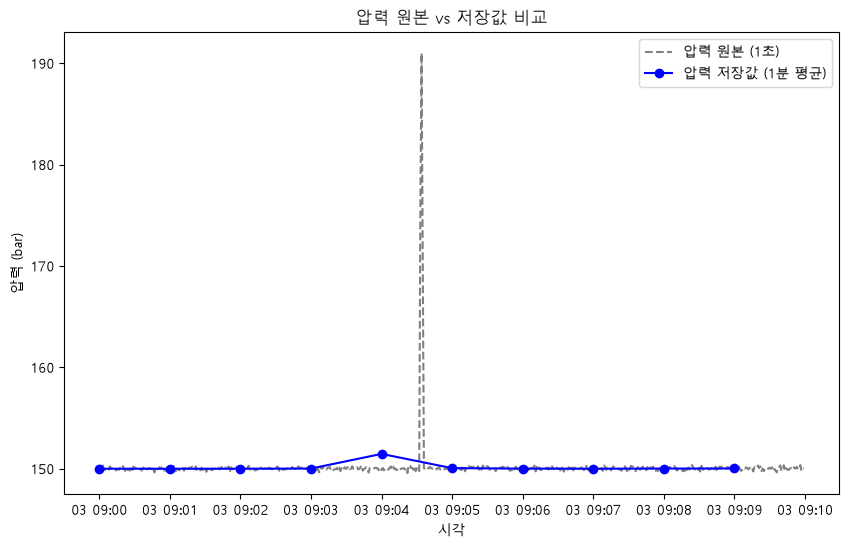

In [117]:
plt.figure(figsize=(10, 6))
plt.plot(pressure_raw["timestamp"], pressure_raw["pressure_bar"],color="gray", linestyle="--", label="압력 원본 (1초)")
plt.plot(pressure_saved["timestamp"], pressure_saved["pressure_bar"], color="blue", marker="o", label="압력 저장값 (1분 평균)")
plt.legend()
plt.xlabel("시각")
plt.ylabel("압력 (bar)")
plt.title("압력 원본 vs 저장값 비교")
plt.show()


In [107]:
#3. 온도 5분 집계와 데드밴드가 짧은 변화를 어떻게 지우는지 설명한다.


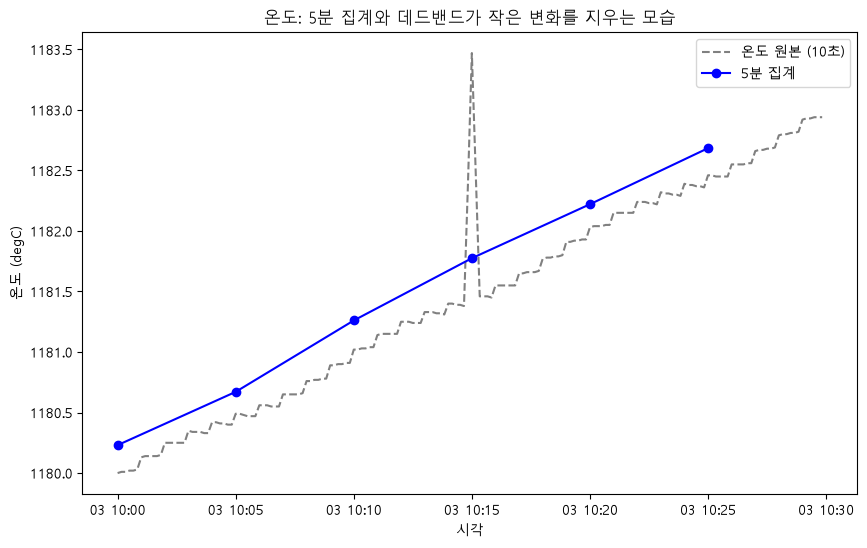

In [115]:
plt.figure(figsize=(10, 6))
plt.plot(temp_raw["timestamp"], temp_raw["furnace_temp_c"], color="gray", linestyle="--", label="온도 원본 (10초)")
plt.plot(temp_saved["timestamp"], temp_saved["furnace_temp_c"], color="blue", marker="o", label="5분 집계")
plt.ylabel("온도 (degC)")
plt.xlabel("시각")
plt.title("온도: 5분 집계와 데드밴드가 작은 변화를 지우는 모습")
plt.legend()
plt.show()

In [ ]:
#3. 온도 5분 집계와 데드밴드가 짧은 변화를 어떻게 지우는지 설명한다.

#5분 집계는 짧은 튐을 5분 평균에 섞어 크기를 희석하고, 
#데드밴드는 직전 저장값과 0.5℃ 미만 차이를 기록하지 않아 작은 변화를 지웁니다.

In [ ]:
#4. 데이터 제공자에게 물을 출처, 원래 주기, 집계법, 데드밴드, 품질 코드 및 강제 저장 항목을 정리한다.


In [ ]:
#각 값의 출처, 원래 주기, 집계 방식, 데드밴드 폭, 품질 코드, 
# 강제 저장 조건을 확인해 달라고 요청합니다.

In [ ]:
#실습 1 | 고장의 진행 구조와 대응 가능성


In [ ]:
#1. 사례를 P-F 곡선에 배치하고 PF간격, 고장 영향, 최초 감지 수단을 비교한다.


In [ ]:
#4-01.pdf 

In [ ]:
# case A

In [119]:
from pathlib import Path

import pandas as pd

# 노트북에서는 __file__이 없으므로 현재 작업 폴더(practice/day32)를 기준으로 합니다.
# 두 단계 위가 저장소 루트입니다.
REPO = Path.cwd().parents[1]
DATA = REPO / "lectures" / "week9" / "04일차_20_261109_16" / "04-01_고장의_진행_구조_고장사례.csv"

if not DATA.exists():
    raise FileNotFoundError(f"데이터 파일이 없습니다: {DATA}")

df = pd.read_csv(DATA)

print("사례 수:", len(df))
# 예상 결과: 사례 수: 8


사례 수: 8


In [144]:
df.columns.tolist()

['사례ID',
 '케이스',
 '설비',
 '고장모드',
 '손상형태',
 '관측신호',
 '최초감지수단',
 'PF간격_일',
 '데이터저장여부',
 '저장주기_분',
 '정지영향',
 '대응가능',
 '권장점검주기_일']

In [134]:
리드타임 = 20
df["대응가능"] = df["PF간격_일"] > 리드타임


In [136]:
df["권장점검주기_일"] = df["PF간격_일"] / 2


In [139]:
실습1 = df[["사례ID", "설비", "PF간격_일", "권장점검주기_일", "대응가능"]]
실습1

,사례ID,설비,PF간격_일,권장점검주기_일,대응가능
0,A1,모터,90,45.0,True
1,A2,급기팬,45,22.5,True
2,A3,공기압축기,120,60.0,True
3,A4,감속기,0,0.0,False
4,B1,유압 유닛,30,15.0,True
5,B2,가열로,180,90.0,True
6,B3,컨베이어,0,0.0,False
7,B4,롤러테이블,10,5.0,False


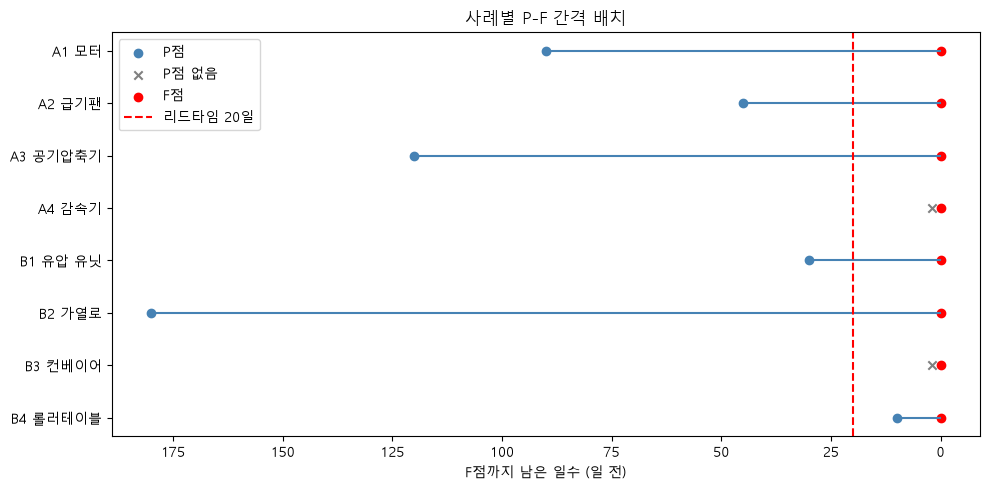

In [143]:

y = np.arange(len(df))
pf = df["PF간격_일"].to_numpy()
has_p = pf > 0  

fig, ax = plt.subplots(figsize=(10, 5))

ax.hlines(y[has_p], xmin=0, xmax=pf[has_p], color="steelblue")
ax.scatter(pf[has_p], y[has_p], color="steelblue", label="P점")

ax.scatter(pf[~has_p] + 2, y[~has_p], marker="x", color="gray", label="P점 없음")

ax.scatter(np.zeros(len(df)), y, color="red", label="F점")

ax.axvline(리드타임, color="red", linestyle="--", label=f"리드타임 {리드타임}일")
ax.set_yticks(y)
ax.set_yticklabels(df["사례ID"] + " " + df["설비"])
ax.invert_yaxis()   # A1이 위에 오도록
ax.invert_xaxis()   # 왼쪽이 과거, 오른쪽이 F점
ax.set_xlabel("F점까지 남은 일수 (일 전)")
ax.set_title("사례별 P-F 간격 배치")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
#2. P-F 간격의 절반 이하 점검 주기와 실제 저장 주기를 구분한다.


In [145]:

df["권장점검주기_일"] = df["PF간격_일"] / 2

# 실제 저장 주기: 분 → 일
df["저장주기_일"] = df["저장주기_분"] / (60 * 24)

df["구분결과"] = np.where(
    df["데이터저장여부"] != "Y", "기록 없음",
    np.where(df["저장주기_일"] <= df["권장점검주기_일"], "권장 이내", "권장 초과"),
)

구분표 = df[["사례ID", "설비", "PF간격_일", "권장점검주기_일", "저장주기_분", "저장주기_일", "구분결과"]].round(4)
구분표


,사례ID,설비,PF간격_일,권장점검주기_일,저장주기_분,저장주기_일,구분결과
0,A1,모터,90,45.0,10,0.0069,권장 이내
1,A2,급기팬,45,22.5,10,0.0069,권장 이내
2,A3,공기압축기,120,60.0,60,0.0417,권장 이내
3,A4,감속기,0,0.0,0,0.0000,기록 없음
4,B1,유압 유닛,30,15.0,5,0.0035,권장 이내
5,B2,가열로,180,90.0,0,0.0000,기록 없음
6,B3,컨베이어,0,0.0,0,0.0000,기록 없음
7,B4,롤러테이블,10,5.0,30,0.0208,권장 이내


In [155]:
df["리드타임7"] = ((df["PF간격_일"] > 0) & (df["PF간격_일"] >= 7)).map({True: "가능", False: "불가"})
df["리드타임30"] = ((df["PF간격_일"] > 0) & (df["PF간격_일"] >= 30)).map({True: "가능", False: "불가"})
df["판정변화"] = df["리드타임7"] != df["리드타임30"]   # 두 결과가 다르면 True

표 = df[["사례ID", "설비", "PF간격_일", "리드타임7", "리드타임30", "판정변화"]]
표



,사례ID,설비,PF간격_일,리드타임7,리드타임30,판정변화
0,A1,모터,90,가능,가능,False
1,A2,급기팬,45,가능,가능,False
2,A3,공기압축기,120,가능,가능,False
3,A4,감속기,0,불가,불가,False
4,B1,유압 유닛,30,가능,가능,False
5,B2,가열로,180,가능,가능,False
6,B3,컨베이어,0,불가,불가,False
7,B4,롤러테이블,10,가능,불가,True


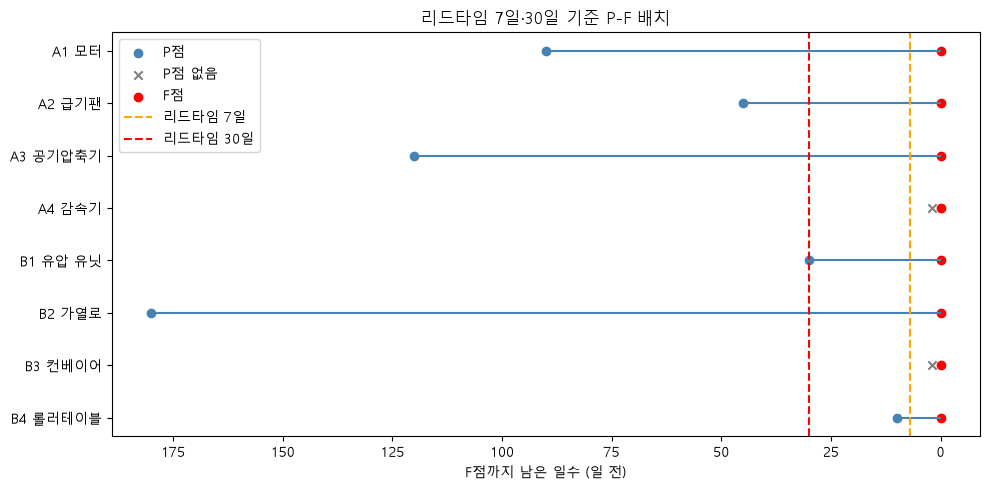

In [161]:
y = np.arange(len(df))
pf = df["PF간격_일"].to_numpy()
has_p = pf > 0

fig, ax = plt.subplots(figsize=(10, 5))

ax.hlines(y[has_p], xmin=0, xmax=pf[has_p], color="steelblue")
ax.scatter(pf[has_p], y[has_p], color="steelblue", label="P점")

ax.scatter(pf[~has_p] + 2, y[~has_p], marker="x", color="gray", label="P점 없음")

ax.scatter(np.zeros(len(df)), y, color="red", label="F점")

ax.axvline(7, color="orange", linestyle="--", label="리드타임 7일")
ax.axvline(30, color="red", linestyle="--", label="리드타임 30일")

ax.set_yticks(y)
ax.set_yticklabels(df["사례ID"] + " " + df["설비"])
ax.invert_yaxis()    # A1이 위에 오도록
ax.invert_xaxis()    # 왼쪽이 과거, 오른쪽이 F점
ax.set_xlabel("F점까지 남은 일수 (일 전)")
ax.set_title("리드타임 7일·30일 기준 P-F 배치")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
#4. 물리적 돌발, 간격 부족, 측정 부재에는 각각 다른 대응(이중화, 보호, 계측)을 제안한다.


#A4 감속기, B3 컨베이어  P점이 없어서 예측으로 막기 어렵다.  
이중화  혹은  개선 제안

In [ ]:
# B4 롤러테이블  윤활불량.  보호필요. 맨트작성필요...

In [ ]:
#B2 가열로 는 열화상 순회 점검 중.  계측필요.  외벽 온도 센서 등등,,,